# Algoritmo de Kadane

Encuentra el subarray contiguo de suma máxima en $O(n)$. En cada posición decide si es mejor continuar el subarray anterior o empezar uno nuevo: $\text{mejor\_aquí} = \max(x, \text{mejor\_aquí} + x)$.

## 1. Suma máxima

Devolver la suma máxima de un subarray contiguo (no vacío).

In [1]:
def kadane(lista):
    mejor = actual = lista[0]
    for x in lista[1:]:
        actual = max(x, actual + x)
        mejor = max(mejor, actual)
    return mejor

print(kadane([-2, 1, -3, 4, -1, 2, 1, -5, 4]), kadane([-3, -1, -2]))

6 -1


## 2. Subarray máximo y comprobación

Devolver también los índices del subarray y comprobar el resultado con fuerza bruta $O(n^2)$.

In [2]:
import random

def kadane_indices(lista):
    mejor, actual, inicio, mejor_rango = lista[0], lista[0], 0, (0, 0)
    for i in range(1, len(lista)):
        if lista[i] > actual + lista[i]:
            actual, inicio = lista[i], i
        else:
            actual += lista[i]
        if actual > mejor:
            mejor, mejor_rango = actual, (inicio, i)
    return mejor, mejor_rango

def fuerza_bruta(lista):
    return max(sum(lista[i:j + 1]) for i in range(len(lista)) for j in range(i, len(lista)))

for _ in range(300):
    datos = [random.randint(-10, 10) for _ in range(random.randint(1, 20))]
    suma, (i, j) = kadane_indices(datos)
    assert suma == fuerza_bruta(datos) == sum(datos[i:j + 1])

datos = [-2, 1, -3, 4, -1, 2, 1, -5, 4]
suma, (i, j) = kadane_indices(datos)
print(suma, datos[i:j + 1])

6 [4, -1, 2, 1]


## 3. Kadane circular con índices

En un array circular el subarray puede dar la vuelta. El máximo es el de Kadane normal o el total menos el subarray de suma mínima (lo que queda fuera); si el mínimo es todo el array, el segundo caso dejaría un subarray vacío y no vale. Devolver la suma y los índices de inicio y fin (el fin es menor que el inicio cuando da la vuelta) y comprobarlo con fuerza bruta sobre todos los subarrays circulares.

In [3]:
def kadane_circular(lista):
    n = len(lista)
    mejor, rango = kadane_indices(lista)
    # subarray mínimo = máximo de los negados
    menos_minimo, (i, j) = kadane_indices([-x for x in lista])
    envolvente = sum(lista) + menos_minimo
    if envolvente > mejor and (i, j) != (0, n - 1):
        return envolvente, ((j + 1) % n, (i - 1) % n)
    return mejor, rango

def suma_circular(lista, i, j):
    n = len(lista)
    return sum(lista[(i + t) % n] for t in range((j - i) % n + 1))

def fuerza_bruta_circular(lista):
    n = len(lista)
    return max(suma_circular(lista, i, (i + largo - 1) % n) for i in range(n) for largo in range(1, n + 1))

random.seed(3)
for _ in range(500):
    datos = [random.randint(-10, 10) for _ in range(random.randint(1, 15))]
    suma, (i, j) = kadane_circular(datos)
    assert suma == fuerza_bruta_circular(datos) == suma_circular(datos, i, j)

for datos in ([5, -3, 5], [8, -1, -3, -6, 2, 9], [-3, -2, -1]):
    suma, (i, j) = kadane_circular(datos)
    print(datos, "→", suma, (i, j))

[5, -3, 5] → 10 (2, 0)
[8, -1, -3, -6, 2, 9] → 19 (4, 0)
[-3, -2, -1] → -1 (2, 2)


## 4. Producto máximo

Variante: encontrar el subarray contiguo de producto máximo. Un número negativo convierte el menor producto en el mayor, así que hay que llevar a la vez el máximo y el mínimo de los productos que terminan en cada posición. Comprobarlo con fuerza bruta.

In [4]:
from math import prod

def producto_maximo(lista):
    mejor = alto = bajo = lista[0]
    for x in lista[1:]:
        candidatos = (x, alto * x, bajo * x)
        alto, bajo = max(candidatos), min(candidatos)
        mejor = max(mejor, alto)
    return mejor

for _ in range(500):
    datos = [random.randint(-5, 5) for _ in range(random.randint(1, 12))]
    n = len(datos)
    assert producto_maximo(datos) == max(prod(datos[i:j + 1]) for i in range(n) for j in range(i, n))
print(producto_maximo([2, 3, -2, 4]), producto_maximo([-2, 3, -4]))

6 24


## 5. Comprar y vender acciones

Con los precios diarios de una acción, elegir el día de compra y el de venta (posterior) que dan más ganancia. Es Kadane sobre las diferencias entre días consecutivos. Comprobarlo con fuerza bruta y dibujar los precios marcando la compra y la venta.

Comprar el día 26 a 47 y vender el día 29 a 58: +11


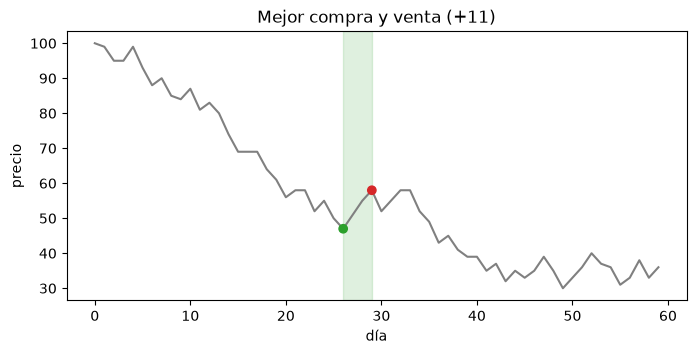

In [5]:
import matplotlib.pyplot as plt

def mejor_operacion(precios):
    diferencias = [b - a for a, b in zip(precios, precios[1:])]
    ganancia, (i, j) = kadane_indices(diferencias)
    return (ganancia, i, j + 1) if ganancia > 0 else (0, None, None)

for _ in range(300):
    precios = [random.randint(1, 50) for _ in range(random.randint(2, 15))]
    ganancia, compra, venta = mejor_operacion(precios)
    n = len(precios)
    assert ganancia == max(0, max(precios[j] - precios[i] for i in range(n) for j in range(i + 1, n)))
    if compra is not None:
        assert precios[venta] - precios[compra] == ganancia

random.seed(7)
precios = [100]
for _ in range(59):
    precios.append(max(1, precios[-1] + random.randint(-6, 6)))
ganancia, compra, venta = mejor_operacion(precios)
print(f"Comprar el día {compra} a {precios[compra]} y vender el día {venta} a {precios[venta]}: +{ganancia}")

fig, eje = plt.subplots(figsize=(8, 3.5))
eje.plot(precios, color="gray")
eje.axvspan(compra, venta, color="tab:green", alpha=0.15)
eje.scatter([compra, venta], [precios[compra], precios[venta]], color=["tab:green", "tab:red"], zorder=3)
eje.set_title(f"Mejor compra y venta (+{ganancia})")
eje.set_xlabel("día")
eje.set_ylabel("precio")
plt.show()